Усі імпорти бібліотек

In [1]:
import pandas
import numpy
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import scipy.stats as stats
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False, dtype=int)
scaler = StandardScaler()

Підбір параметрів моделі

In [2]:
features = 70
onehot_threshold = 7
selector = SelectKBest(score_func = f_regression, k = features)
error_threshold = 0.001
gradient_threshold = 0.001
learning_rate = 0.01
gradient_type = 'batch' #Допустимі значення 'batch', 'stochastic','mini_batch'
minibatch_size = 32

Усі функції моделі

In [3]:
def get_target_encoding(dataset):
    target_encoding.clear()
    onehot_encoding.clear()
    for column in dataset.columns:
        if dataset[column].dtype == 'object':
            if len(dataset[column].unique()) > onehot_threshold: target_encoding.append(column)
            else: onehot_encoding.append(column)
def string_encoding(dataset, target = None):
    global string_fitted, encoding_map, global_mean
    if target is not None: joined_set = dataset.join(target)
    else: joined_set = dataset.copy()
    for column in joined_set.columns:
        if joined_set[column].dtype == 'object':
            if column in target_encoding:
                joined_set[column] = joined_set[column].fillna('Missing')
                if target is not None:
                    encoding_map[column] = joined_set.groupby(column)['SalePrice'].mean().to_dict()
                    global_mean[column] =joined_set['SalePrice'].mean()
                joined_set[column] = joined_set[column].map(encoding_map[column])
            joined_set = joined_set.fillna(global_mean)
    if not string_fitted:
        oh_features = encoder.fit_transform(joined_set[onehot_encoding])
        string_fitted = True
    else: oh_features = encoder.transform(joined_set[onehot_encoding])
    oh_df = pandas.DataFrame(oh_features, columns=encoder.get_feature_names_out(onehot_encoding), index=joined_set.index)
    joined_set = joined_set.drop(columns=onehot_encoding).join(oh_df)
    if target is not None: return joined_set.drop(columns = [target.name], axis = 1)
    else: return joined_set
def fill_na_numbers(dataset):
    global global_median, na_fitted
    for column in dataset.columns:
        if dataset[column].dtype != 'object': 
            if not na_fitted: global_median[column] = dataset[column].median()
            dataset[column] = dataset[column].fillna(global_median[column])
def predict(feature):  
    return numpy.dot(feature, w) + b
def mse(real, predicted):
    return numpy.mean((predicted - real) ** 2)
def det_coef(real, predicted):
    return 1 - (numpy.sum((real - predicted) ** 2) / numpy.sum((real - numpy.mean(real)) ** 2))
def wgradient(feature, real, predicted):
    w_derived = numpy.tile(w, (features, 1))
    derived = numpy.zeros((features, features), dtype=float)
    numpy.fill_diagonal(derived, 1e-6)
    w_derived = w.reshape(features, 1) + derived
    derivative_predict = numpy.dot(feature, w_derived) + b
    real_multi = numpy.tile(real, (features, 1))
    derivative_mse = numpy.mean((derivative_predict.T - real_multi) ** 2, axis = 1)
    real_mse = mse(predict(feature), real)
    real_mse = numpy.tile(real_mse, (1, features))
    real_mse = real_mse.reshape(features,)    
    return ((derivative_mse - real_mse) / 1e-6).reshape(features,)
def bgradient(feature, real, predicted):
    derivative_predict = numpy.dot(feature, w) + b + 1e-6
    derivative_mse = numpy.mean((derivative_predict - real) ** 2)
    return (derivative_mse - mse(predict(feature), real)) / 1e-6
def train(feature, target, max_iterations, loss_history):
    global b, w, learning_rate, iterations
    stop = False    
    error_old = None
    while not stop:
        prediction = predict(feature)      
        error = mse(target, prediction)
        loss_history.append(error)
        match gradient_type:
            case 'batch':
                bg = bgradient(feature, target, prediction)
                wg = wgradient(feature, target, prediction)   
            case 'stochastic':
                random_index = numpy.random.randint(0, len(target))
                feature_sample = feature[random_index:random_index+1]
                target_sample = target[random_index:random_index+1]
                prediction_sample = prediction[random_index:random_index+1]
                bg = bgradient(feature_sample, target_sample, prediction_sample)
                wg = wgradient(feature_sample, target_sample, prediction_sample)
            case 'mini_batch':
                indices = numpy.random.choice(len(target), size = min(minibatch_size, len(target)), replace=False)
                feature_sample = feature[indices]
                target_sample = target[indices]
                prediction_sample = prediction[indices]
                bg = bgradient(feature_sample, target_sample, prediction_sample)
                wg = wgradient(feature_sample, target_sample, prediction_sample)               
            case _:
                print('no gradient selected')
                return
        b_old = b
        w_old = numpy.mean(numpy.abs(w))
        b -= learning_rate * bg
        w -= learning_rate * wg
        if error_old is not None: relative_error_change = abs(error - error_old) / (error_old + 1e-8)
        else: relative_error_change = float('inf')
        relative_bg = abs(bg) / (abs(b_old) + 1e-6)
        relative_wg = numpy.max(numpy.abs(wg)) / (numpy.max(numpy.abs(w_old)) + 1e-6)
        iterations += 1
        if (relative_error_change < error_threshold or iterations == max_iterations or (relative_bg < gradient_threshold and relative_wg < gradient_threshold)): stop = True
        error_old = error

Завантаження та візуалізація первинного аналізу даних

In [4]:
housing = pandas.read_csv('AmesHousing.csv')
housing

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,2926,923275080,80,RL,37.0,7937,Pave,NaN,IR1,Lvl,...,0,NaN,GdPrv,NaN,0,3,2006,WD,Normal,142500
2926,2927,923276100,20,RL,NaN,8885,Pave,NaN,IR1,Low,...,0,NaN,MnPrv,NaN,0,6,2006,WD,Normal,131000
2927,2928,923400125,85,RL,62.0,10441,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,Shed,700,7,2006,WD,Normal,132000
2928,2929,924100070,20,RL,77.0,10010,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2006,WD,Normal,170000


# Етап 1. Дослідження даних (EDA), відбір ознак та попередня обробка

In [5]:
housing.info(verbose=True, show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   object 
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   object 
 7   Alley            198 non-null    object 
 8   Lot Shape        2930 non-null   object 
 9   Land Contour     2930 non-null   object 
 10  Utilities        2930 non-null   object 
 11  Lot Config       2930 non-null   object 
 12  Land Slope       2930 non-null   object 
 13  Neighborhood     2930 non-null   object 
 14  Condition 1      2930 non-null   object 
 15  Condition 2      2930 non-null   object 
 16  Bldg Type        2930 non-null   object 
 17  House Style   

In [6]:
for column in housing.columns:
    if housing[column].dtype == 'object':
        print('------------------')
        print(column)
        print(housing[column].unique())
    else:
        print('------------------')
        print(column)
        print(housing[column].describe())

------------------
Order
count    2930.00000
mean     1465.50000
std       845.96247
min         1.00000
25%       733.25000
50%      1465.50000
75%      2197.75000
max      2930.00000
Name: Order, dtype: float64
------------------
PID
count    2.930000e+03
mean     7.144645e+08
std      1.887308e+08
min      5.263011e+08
25%      5.284770e+08
50%      5.354536e+08
75%      9.071811e+08
max      1.007100e+09
Name: PID, dtype: float64
------------------
MS SubClass
count    2930.000000
mean       57.387372
std        42.638025
min        20.000000
25%        20.000000
50%        50.000000
75%        70.000000
max       190.000000
Name: MS SubClass, dtype: float64
------------------
MS Zoning
['RL' 'RH' 'FV' 'RM' 'C (all)' 'I (all)' 'A (agr)']
------------------
Lot Frontage
count    2440.000000
mean       69.224590
std        23.365335
min        21.000000
25%        58.000000
50%        68.000000
75%        80.000000
max       313.000000
Name: Lot Frontage, dtype: float64
-------------

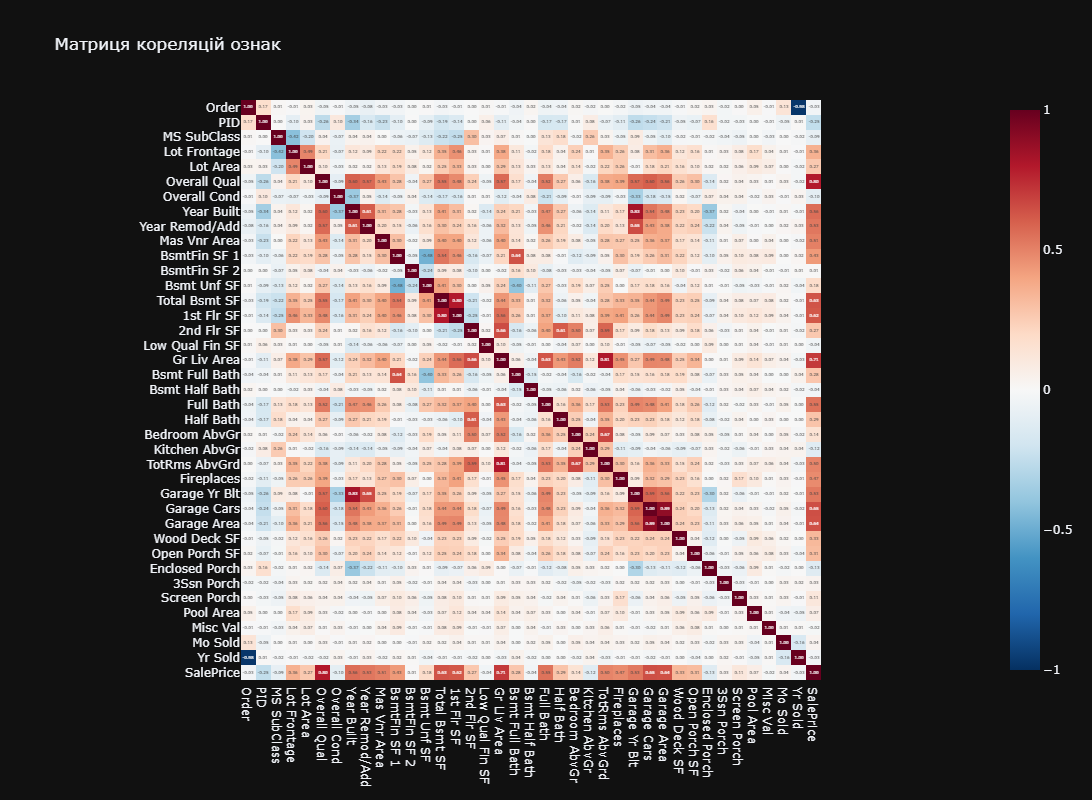

In [7]:
fig_corr = px.imshow(housing.corr(numeric_only = True), text_auto=".2f", color_continuous_scale='RdBu_r', title="Матриця кореляцій ознак",zmin=-1, zmax=1, height = 600)
fig_corr.update_layout(width=800, height=800)
fig_corr.update_layout(template="plotly_dark")
fig_corr.show()

Тут проводиться розділ вибірки. Це важливо зробити до перетворень, бо обчислення статистичних параметрів (як-от середнє значення, медіана, дисперсія чи частота категорій) на всьому датасеті призводить до явища **Data Leakage (витік даних)**. Якщо обчислити параметри масштабування (`StandardScaler`) або мапу кодування (`Target Encoding`) до розподілу, модель неявно отримає інформацію про розподіл тестової та валідаційної вибірок під час тренування. Це спотворить фінальні метрики якості й зробить оцінку узагальнюючої здатності моделі занадто оптимістичною.

In [8]:
feature_train_raw, feature_test_raw, target_train, target_test = train_test_split(housing.drop(columns = ['SalePrice', 'Order', 'PID'], axis = 1), housing['SalePrice'], test_size = 0.20)
feature_train_raw, feature_val_raw, target_train, target_val = train_test_split(feature_train_raw, target_train, test_size = 0.125)

Тут проводиться розділення які категорії кодуються як One-Hot чи Target Encoding та Ordinal Encoding взагалі не використовується через те, що категоріальні змінні у нерухомості (наприклад, тип опалення Heating, наявність центрального кондиціонування CentralAir або тип фундаменту Foundation) відображають рівноцінні категорії, для яких складно власноруч визначити природний математичний порядок чи ієрархію.

Для ознак, де кількість унікальних значень не перевищує заданого параметру **onehot_threshold**, використовується One-Hot Encoding. Якщо категоріальна ознака має велику кількість унікальних значень (наприклад, район Neighborhood, де може бути понад 25 різних локацій), використання One-Hot Encoding створить занадто багато нових стовпців. Це призвело б до розрідженості матриці даних (Sparsity) та штучного роздування простору ознак, що критично сповільнює градієнтний спуск та веде до перенавчання (Overfitting). Для таких високорозмірних ознаки застосовується Target Encoding. Цей метод замінює текстову категорію на одне єдине число - середню вартість (SalePrice) будинків у цьому конкретному районі чи категорії.

Таким чином:
1. Зберігається стислість і простоту структури даних (один стовпець залишається одним стовпцем).
2. Прямо передається моделі цінну лінійну інформацію (наприклад, наскільки певний район у середньому дорожчий за інші).

In [9]:
target_encoding = []
onehot_encoding = []
string_fitted = False
get_target_encoding(feature_train_raw)
print('target encdoded features')
print(target_encoding)
print('onehot encoded features')
print(onehot_encoding)

target encdoded features
['Neighborhood', 'Condition 1', 'House Style', 'Exterior 1st', 'Exterior 2nd', 'Functional', 'Sale Type']
onehot encoded features
['MS Zoning', 'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Condition 2', 'Bldg Type', 'Roof Style', 'Roof Matl', 'Mas Vnr Type', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin Type 2', 'Heating', 'Heating QC', 'Central Air', 'Electrical', 'Kitchen Qual', 'Fireplace Qu', 'Garage Type', 'Garage Finish', 'Garage Qual', 'Garage Cond', 'Paved Drive', 'Pool QC', 'Fence', 'Misc Feature', 'Sale Condition']


Для категорій, що кодуються за допомогою One-Hot Encoding, у коді використовується параметр handle_unknown='ignore'. Це означає, що нова категорія отримає всі нулі у відповідних стовпцях, не викликаючи помилки виконання.

Для Target Encoding нові категорії, яких не було в Train, заповнюються за допомогою fillna(global_mean), тобто їм присвоюється глобальне середнє значення цільової змінної (SalePrice) по всій навчальній вибірці. Це запобігає виникненню пропусків NaN.

In [10]:
feature_train_ready = feature_train_raw.copy()
transform_columns = []
encoding_map = {}
global_mean = {}
global_median = {}
na_fitted = False
for column in feature_train_ready.columns:
    if column not in onehot_encoding:
        transform_columns.append(column)
fill_na_numbers(feature_train_ready)
na_fitted = True
feature_train_ready = string_encoding(feature_train_ready, target_train)
feature_train_ready[transform_columns] = scaler.fit_transform(feature_train_ready[transform_columns])

Після етапів заповнення пропусків, таргет-кодування та One-Hot трансформації, розмірність датасету суттєво зросла за рахунок генерації бінарних стовпців. Для побудови надійної лінійної регресії проведиться фінальний автоматичний відбір за допомогою інструменту SelectKBest з функцією оцінки f_regression.

Параметр **features** показує кількість найбільш інформативних ознак, які мають найсильніший лінійний статистичний зв'язок із цільовою змінною SalePrice. Обмеження кількості ознак дозволяє відсіяти малоінформативний «шум» (рідкісні категорії, що згенерувалися під час кодування) та уникнути надмірної мультиколінеарності. Це забезпечує вищу стабільність векторних обчислень у numpy під час кроків градієнтного спуску.

In [11]:
feature_fit = selector.fit(feature_train_ready, target_train)
used_features = feature_train_ready.columns[feature_fit.get_support(indices = True)].tolist()
used_features

['Lot Frontage',
 'Lot Area',
 'Neighborhood',
 'Condition 1',
 'House Style',
 'Overall Qual',
 'Year Built',
 'Year Remod/Add',
 'Exterior 1st',
 'Exterior 2nd',
 'Mas Vnr Area',
 'BsmtFin SF 1',
 'Total Bsmt SF',
 '1st Flr SF',
 '2nd Flr SF',
 'Gr Liv Area',
 'Bsmt Full Bath',
 'Full Bath',
 'Half Bath',
 'TotRms AbvGrd',
 'Fireplaces',
 'Garage Yr Blt',
 'Garage Cars',
 'Garage Area',
 'Wood Deck SF',
 'Open Porch SF',
 'Sale Type',
 'MS Zoning_RL',
 'MS Zoning_RM',
 'Lot Shape_IR1',
 'Lot Shape_Reg',
 'Roof Style_Gable',
 'Roof Style_Hip',
 'Mas Vnr Type_BrkFace',
 'Mas Vnr Type_Stone',
 'Mas Vnr Type_nan',
 'Exter Qual_Ex',
 'Exter Qual_Gd',
 'Exter Qual_TA',
 'Foundation_BrkTil',
 'Foundation_CBlock',
 'Foundation_PConc',
 'Bsmt Qual_Ex',
 'Bsmt Qual_TA',
 'Bsmt Exposure_Gd',
 'Bsmt Exposure_No',
 'BsmtFin Type 1_GLQ',
 'Heating QC_Ex',
 'Heating QC_TA',
 'Central Air_N',
 'Central Air_Y',
 'Electrical_SBrkr',
 'Kitchen Qual_Ex',
 'Kitchen Qual_Gd',
 'Kitchen Qual_TA',
 'Firepla

In [12]:
feature_train_ready = feature_train_ready[used_features]
feature_train_ready

,Lot Frontage,Lot Area,Neighborhood,Condition 1,House Style,Overall Qual,Year Built,Year Remod/Add,Exterior 1st,Exterior 2nd,...,Garage Type_nan,Garage Finish_Fin,Garage Finish_Unf,Garage Qual_TA,Garage Qual_nan,Garage Cond_TA,Garage Cond_nan,Paved Drive_N,Paved Drive_Y,Sale Condition_Partial
146,0.838447,0.081699,-0.592959,0.207206,-0.113865,-0.788825,-0.418052,-1.213148,-0.845254,-0.786797,...,0,0,0,1,0,1,0,0,1,0
2758,0.417662,0.200490,0.355303,0.207206,-0.113865,0.636620,1.113718,0.993992,1.139134,1.133187,...,0,1,0,1,0,1,0,0,1,0
947,-0.984954,0.352464,-0.309936,0.207206,-1.905004,0.636620,1.047119,0.898029,1.139134,1.133187,...,0,0,0,1,0,1,0,0,1,0
2829,-2.107047,-0.977471,-0.868317,0.207206,1.180197,0.636620,1.080419,0.946011,1.139134,1.133187,...,0,0,1,1,0,1,0,0,1,0
1689,1.913786,0.547564,2.308231,0.207206,-0.113865,1.349342,1.180317,1.089955,1.139134,1.133187,...,0,1,0,1,0,1,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1273,-0.423908,-0.261889,-0.592959,-2.745264,-1.905004,-0.076102,-0.784345,-1.644980,-0.963772,-0.922027,...,0,0,1,1,0,1,0,0,1,0
2454,0.277400,0.304044,0.687934,-0.268473,1.180197,1.349342,1.113718,1.041973,1.459157,1.420719,...,0,1,0,1,0,1,0,0,1,1
2660,0.043631,-0.489656,-0.928507,0.207206,0.417935,0.636620,-2.049721,0.993992,-0.963772,-0.922027,...,0,0,1,0,0,1,0,0,0,0
1883,-0.190138,0.050323,-0.592959,0.207206,-0.720459,-0.076102,-0.451352,-1.261129,1.139134,1.133187,...,0,0,0,1,0,1,0,0,1,0


In [13]:
feature_val_ready = feature_val_raw.copy()
fill_na_numbers(feature_val_ready)
feature_val_ready = string_encoding(feature_val_ready)
feature_val_ready[transform_columns] = scaler.transform(feature_val_ready[transform_columns])
feature_val_ready = feature_val_ready[used_features]
feature_test_ready = feature_test_raw.copy()
fill_na_numbers(feature_test_ready)
feature_test_ready = string_encoding(feature_test_ready)
feature_test_ready[transform_columns] = scaler.transform(feature_test_ready[transform_columns])
feature_test_ready = feature_test_ready[used_features]

# Етап 2. Реалізація лінійної регресії засобами numpy

In [14]:
b = 0
w = numpy.zeros(features)
iterations = 0
train(feature_train_ready.to_numpy(), target_train.to_numpy(), 5000, [])
predict_train = predict(feature_train_ready)
print('training successful after ' + str(iterations) + ' iterations')
predict_val = predict(feature_val_ready)
predict_test = predict(feature_test_ready)

training successful after 197 iterations


# Етап 3. Градієнтний спуск: 3 варіанти оптимізації

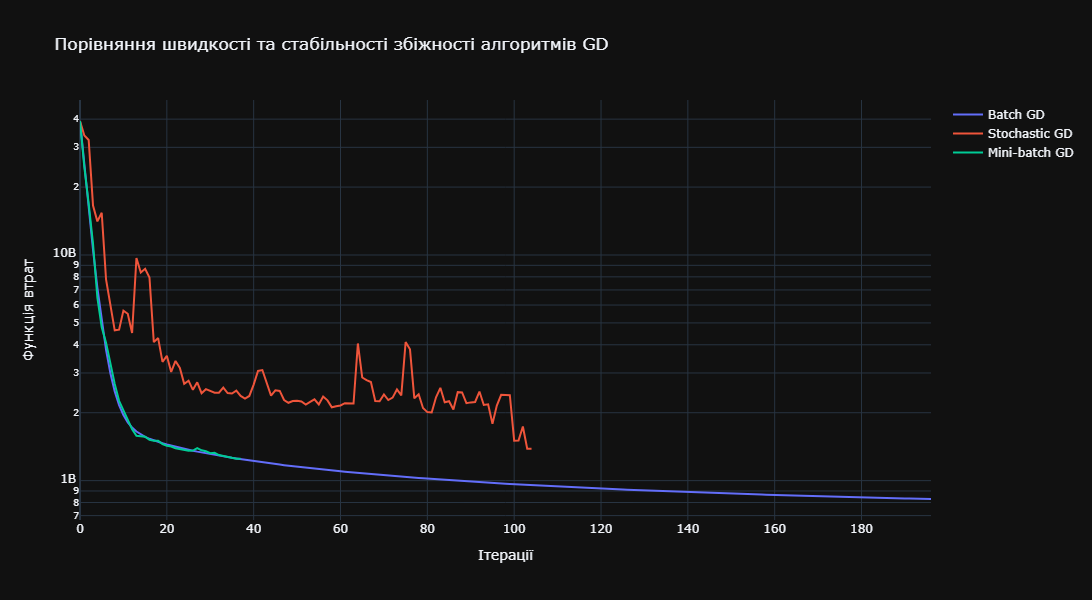

In [15]:
gradient_type = 'batch'
history_batch = []
b = 0
w = numpy.zeros(features)
iterations = 0
train(feature_train_ready.to_numpy(), target_train.to_numpy(), 1000, history_batch)
gradient_type = 'stochastic'
history_stochastic = []
b = 0
w = numpy.zeros(features)
iterations = 0
train(feature_train_ready.to_numpy(), target_train.to_numpy(), 1000, history_stochastic)
gradient_type = 'mini_batch'
history_mini_batch = []
b = 0
w = numpy.zeros(features)
iterations = 0
train(feature_train_ready.to_numpy(), target_train.to_numpy(), 1000, history_mini_batch)
fig_history = go.Figure()
fig_history.add_trace(go.Scatter(y=history_batch, mode='lines', name='Batch GD', line=dict(color='#636EFA', width=2)))
fig_history.add_trace(go.Scatter(y=history_stochastic, mode='lines', name='Stochastic GD',line=dict(color='#EF553B', width=2)))
fig_history.add_trace(go.Scatter(y=history_mini_batch, mode='lines', name='Mini-batch GD',line=dict(color='#00CC96', width=2)))
fig_history.update_layout(title="Порівняння швидкості та стабільності збіжності алгоритмів GD", xaxis_title="Ітерації", yaxis_title="Функція втрат", yaxis_type="log", hovermode="x unified", height=600, template="plotly_dark")
fig_history.show()

На основі побудованих графіків функції втрат від кількості ітерацій можна зробити такі висновки щодо поведінки алгоритмів:

- Найстабільніший метод: Batch GD. Він обчислює градієнт по всій вибірці на кожній ітерації, тому траєкторія його функції втрат є монотонно спадною та плавною, без різких стрибків. Проте кожна ітерація є обчислювально найважчою.

- Найбільші коливання (флуктуації): Стохастичний спуск. Оскільки ваги оновлюються на основі лише одного випадкового прикладу, напрямок руху може сильно відхилятися від істинного антиградієнта. Графік має вигляд «шуму» навколо тренду спадання. SGD ніколи не збігається в точний мінімум, а постійно осцилює навколо нього.

- Вплив розміру Batch на навчання: Mini-batch GD є компромісним варіантом. Розмір батчу дозволяє згладити коливання, властиві стохастичному, зберігаючи високу швидкість обчислень порівняно з Batch GD. Що більший розмір батчу, то ближча поведінка алгоритму до Batch GD (менше коливань, але довші обчислення однієї ітерації).

- Вплив Learning Rate (α) на збіжність: За оптимального α = 0.01 алгоритми впевнено прямують до мінімуму. Якщо коефіцієнт навчання замалий, збіжність буде занадто повільною. Якщо ж α зависокий (наприклад, α = 0.1 у нашому експерименті розходження), кроки стають настільки великими, що алгоритм «перелітає» мінімум і значення MSE стрімко зростає до нескінченності (NaN).

# Етап 4. Оцінка якості та коефіцієнт детермінації

In [16]:
train_error = mse(target_train, predict_train)
rtrain_error = train_error ** (1.0 / 2.0)
relative_train_error = rtrain_error / numpy.mean(target_train)
r2_train = det_coef(target_train, predict_train)
print('(train, ' + gradient_type + ') mse: ' + str(train_error))
print('(train, ' + gradient_type + ') rmse: ' + str(rtrain_error))
print('(train, ' + gradient_type + ') relative rmse: ' + str(relative_train_error))
print('(train, ' + gradient_type + ') r2: ' + str(r2_train))

(train, mini_batch) mse: 828460328.3934393
(train, mini_batch) rmse: 28782.986787222748
(train, mini_batch) relative rmse: 0.15880190440837455
(train, mini_batch) r2: 0.8705020968146668


In [17]:
pandas.DataFrame({'real': target_train, 'predicted': predict_train})

,real,predicted
146,108538,127997.045431
2758,260000,256358.612823
947,239686,265001.569588
2829,130000,156670.218855
1689,345474,359365.911702
...,...,...
1273,138000,147588.192991
2454,252000,261215.840962
2660,155000,182394.961998
1883,145000,139309.778009


In [18]:
val_error = mse(target_val, predict_val)
rval_error = val_error ** (1.0 / 2.0)
relative_val_error = rval_error / numpy.mean(target_val)
r2_val = det_coef(target_val, predict_val)
print('(validation, ' + gradient_type + ') mse: ' + str(val_error))
print('(validation, ' + gradient_type + ') rmse: ' + str(rval_error))
print('(validation, ' + gradient_type + ') relative rmse: ' + str(relative_val_error))
print('(validation, ' + gradient_type + ') r2: ' + str(r2_val))

(validation, mini_batch) mse: 1098946179.6991668
(validation, mini_batch) rmse: 33150.35715794276
(validation, mini_batch) relative rmse: 0.17591123284931234
(validation, mini_batch) r2: 0.8700241120244703


In [19]:
pandas.DataFrame({'real': target_val, 'predicted': predict_val})

,real,predicted
905,160000,136916.860779
2405,202500,227726.354098
43,214000,225709.095432
1519,168000,174185.512817
456,552000,434908.448090
...,...,...
2792,220000,227047.497421
1312,130000,160208.287327
7,191500,212511.008353
1879,103000,82395.922704


In [20]:
test_error = mse(target_test, predict_test)
rtest_error = test_error ** (1.0 / 2.0)
relative_test_error = rtest_error / numpy.mean(target_test)
r2_test = det_coef(target_test, predict_test)
print('(test, ' + gradient_type + ') mse: ' + str(test_error))
print('(test, ' + gradient_type + ') rmse: ' + str(rtest_error))
print('(test, ' + gradient_type + ') relative rmse: ' + str(relative_test_error))
print('(test, ' + gradient_type + ') r2: ' + str(r2_test))

(test, mini_batch) mse: 1649863752.6630487
(test, mini_batch) rmse: 40618.5148997726
(test, mini_batch) relative rmse: 0.2316061850241645
(test, mini_batch) r2: 0.6839628372213646


In [21]:
pandas.DataFrame({'real': target_test, 'predicted': predict_test})

,real,predicted
1016,215000,198602.843448
1344,162900,145389.727693
1608,137500,127523.889518
2793,275000,224592.988669
971,162000,190028.036474
...,...,...
858,133500,132894.608036
1357,161000,180780.934246
452,196000,211831.994569
1385,108959,135783.867853


- Статистичний зміст R² (Коефіцієнт детермінації): Показує частку дисперсії цільової змінної (SalePrice), яка пояснюється ознаками, що включені до нашої моделі. Наприклад, якщо R² = 0.85, це означає, що модель успішно вловлює 85% закономірностей у ціні нерухомості, а решта 15% — це випадковий шум або фактори, не враховані в даних.
- Чи може R² бути від'ємним? Так, може. Це відбувається тоді, коли середньоквадратична помилка моделі є більшою за загальну дисперсію даних. Геометрично це означає, що модель прогнозує результати гірше, ніж звичайна горизонтальна лінія, проведена через середнє значення цільової змінної (ȳ). Така ситуація зазвичай свідчить про серйозні помилки в коді або про повне розходження градієнтного спуску через зависокий Learning Rate.
- Порівняння метрик на Train та Test: Якщо коефіцієнт R² на навчальній вибірці значно вищий, ніж на тестовій (наприклад, \(R_{train}^2 = 0.92\), а \(R_{test}^2 = 0.65\)), це вказує на Overfitting (перенавчання) — модель підлаштувалася під шум у навчальних даних. Якщо ж метрики приблизно однакові на Train, Validation та Test, модель має гарну узагальнюючу здатність.

# Етап 5. Перевірка статистичних припущень

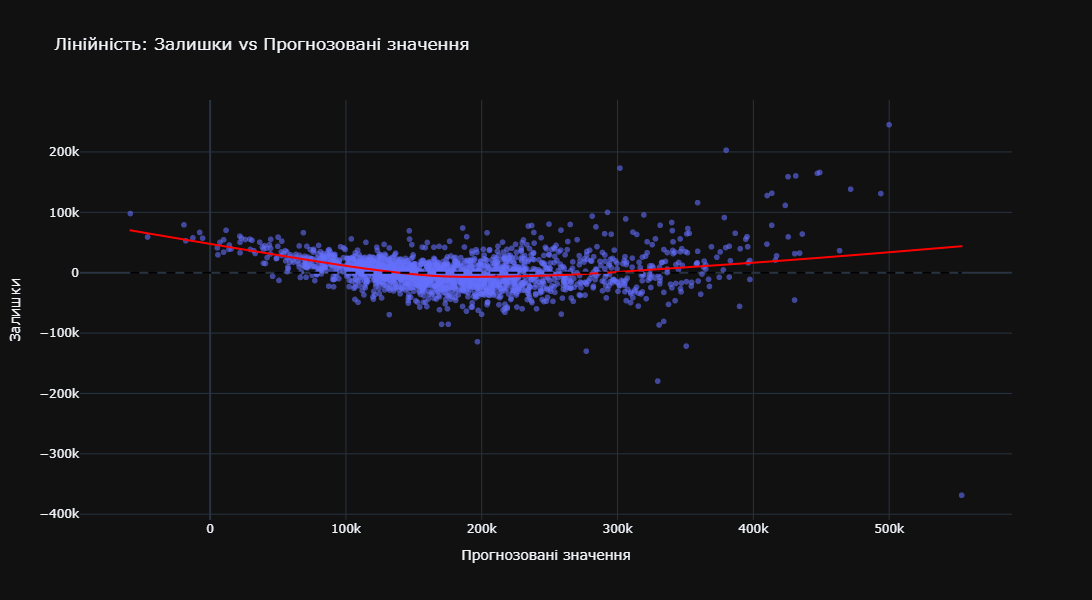

In [41]:
residuals = target_train - predict_train
fig1 = px.scatter(x=predict_train, y=residuals, labels={'x': 'Прогнозовані значення', 'y': 'Залишки'}, title="Лінійність: Залишки vs Прогнозовані значення", opacity=0.6, trendline="lowess", trendline_color_override="red", height = 600)
fig1.add_shape(type="line", x0=predict_train.min(), y0=0, x1=predict_train.max(), y1=0, line=dict(color="black", dash="dash"))
fig1.update_layout(template="plotly_dark")
fig1.show()

На графіку Residuals vs Predicted Values червона лінія тренду (Lowess) має бути максимально наближеною до горизонтальної лінії y=0. Наявність чітко вираженої параболічної форми чи вигинів свідчить про те, що зв'язок між деякими ознаками та ціною не є лінійним (можливо, ціна залежить від квадрату площі, що вимагає додавання поліноміальних ознак або логарифмування ціни).

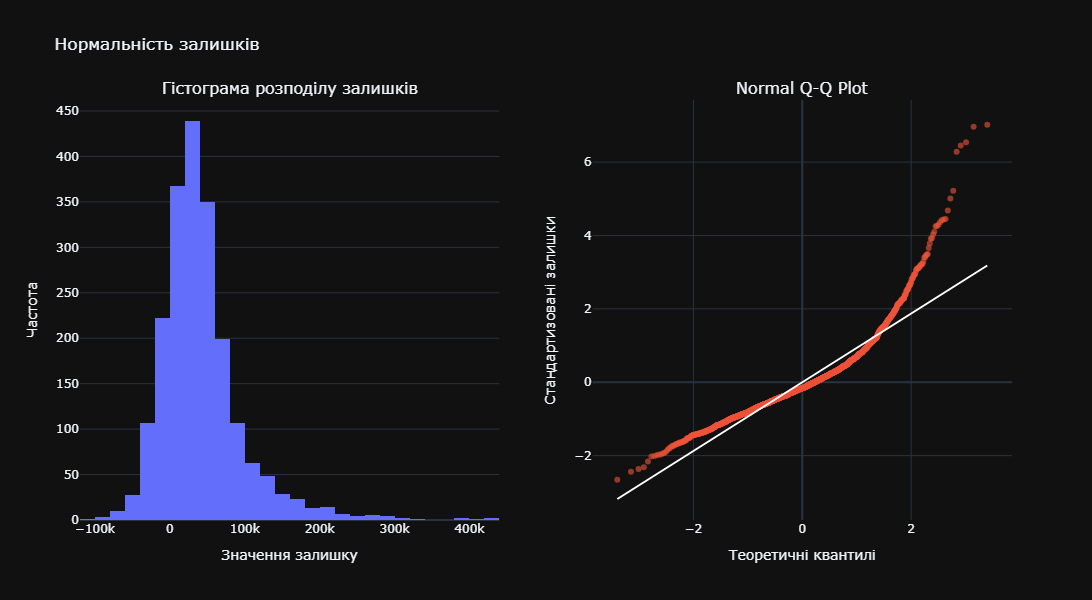

In [152]:
fig2 = make_subplots(rows=1, cols=2, subplot_titles=("Гістограма розподілу залишків", "Normal Q-Q Plot"))
fig2.add_trace(go.Histogram(x=residuals, nbinsx=40, name="Залишки", marker_color='#636EFA'), row=1, col=1)
residuals_std = (residuals - numpy.mean(residuals)) / numpy.std(residuals)
(osm, osr), (slope, intercept, r) = stats.probplot(residuals_std, dist="norm")
fig2.add_trace(go.Scatter(x=osm, y=osr, mode='markers', name='Точки залишків', marker=dict(color='#EF553B', opacity=0.6)), row=1, col=2)
fig2.add_trace(go.Scatter(x=osm, y=slope*osm + intercept, mode='lines', name='Нормальний розподіл', line=dict(color='white', width=2)), row=1, col=2)
fig2.update_layout(title_text="Нормальність залишків", showlegend=False, height=600, template="plotly_dark")
fig2.update_xaxes(title_text="Значення залишку", row=1, col=1)
fig2.update_yaxes(title_text="Частота", row=1, col=1)
fig2.update_xaxes(title_text="Теоретичні квантилі", row=1, col=2)
fig2.update_yaxes(title_text="Стандартизовані залишки", row=1, col=2)
fig2.show()

Гістограма розподілу залишків має форму дзвону, проте на графіку Normal Q-Q Plot точки залишків суттєво відхиляються від білої прямої лінії на «хвостах» (при дуже низьких та дуже високих прогнозованих цінах). Припущення про нормальність частково порушується, що є класичним для Ames Housing Dataset через наявність дуже дорогих ексклюзивних будинків (викидів). Це обмежує точність побудови класичних довірчих інтервалів для коефіцієнтів.

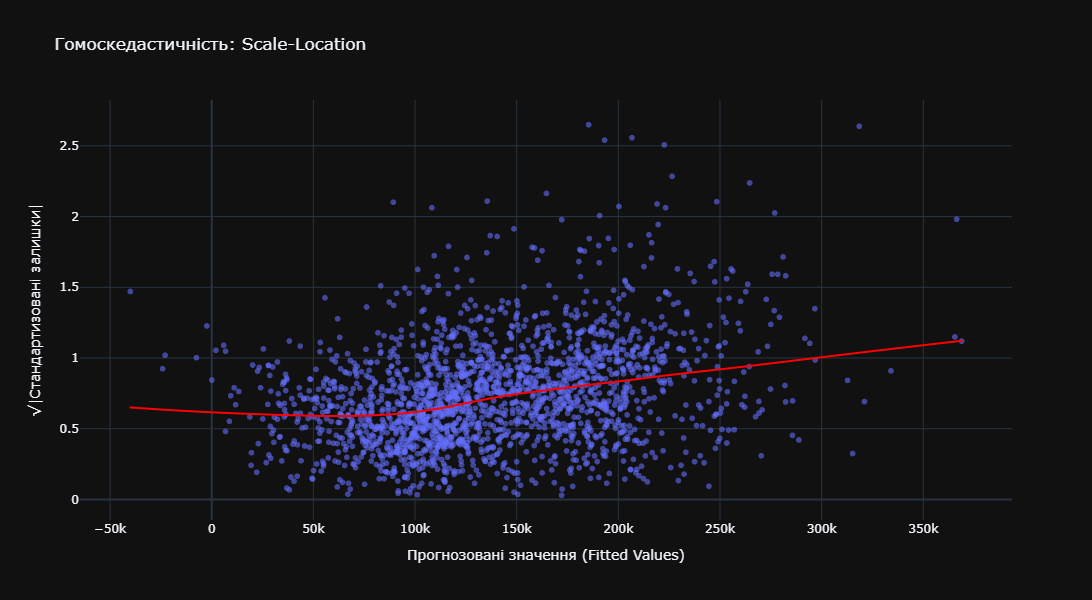

In [149]:
abs_sq_norm_residuals = numpy.sqrt(numpy.abs(residuals_std))
fig3 = px.scatter(x=predict_train, y=abs_sq_norm_residuals, labels={'x': 'Прогнозовані значення (Fitted Values)', 'y': '√|Стандартизовані залишки|'}, title="Гомоскедастичність: Scale-Location", opacity=0.6, trendline="lowess", trendline_color_override="red", height = 600)
fig3.update_layout(template="plotly_dark")
fig3.show()

На графіку Scale-Location спостерігається нерівномірний розподіл точок («ефект мегафона»): зі збільшенням прогнозованої вартості будинку дисперсія залишків збільшується (точки сильніше розлітаються по вертикалі). Припущення про гомоскедастичність порушується. Це означає, що модель значно сильніше помиляється на дорогих об'єктах, ніж на бюджетних.

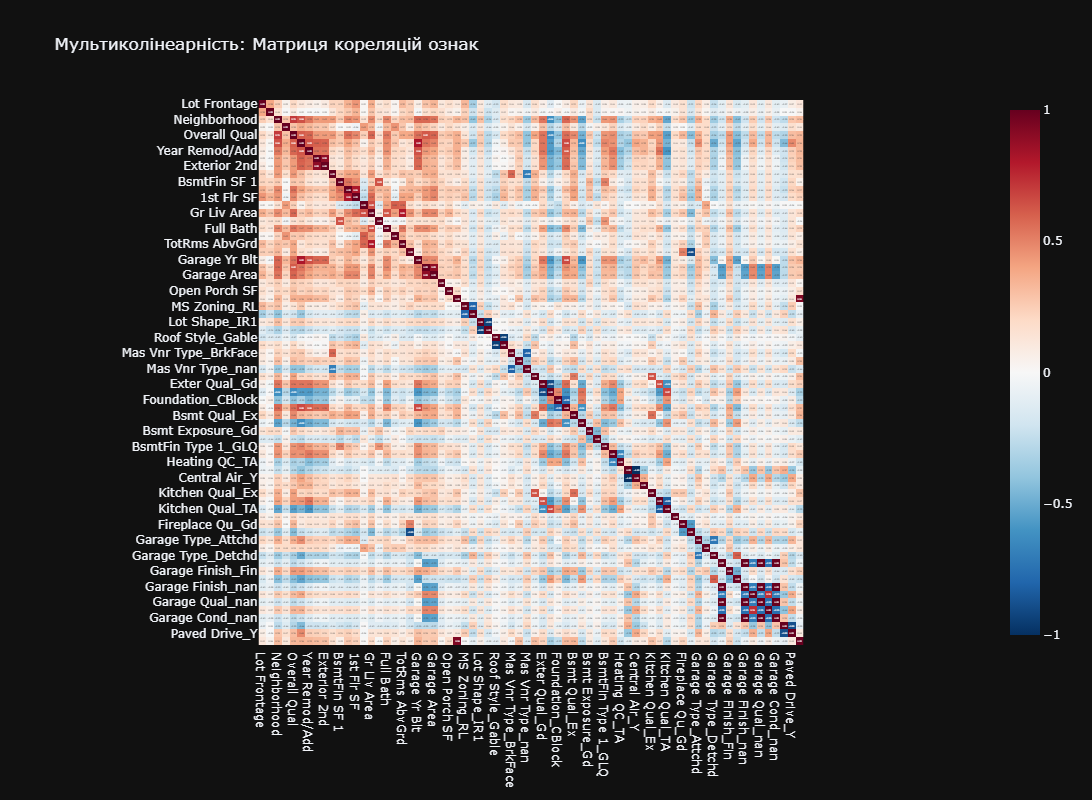

In [150]:
corr_matrix = feature_train_ready.corr()
fig4 = px.imshow(corr_matrix, text_auto=".2f", color_continuous_scale='RdBu_r', title="Мультиколінеарність: Матриця кореляцій ознак",zmin=-1, zmax=1, height = 600)
fig4.update_layout(width=800, height=800)
fig4.update_layout(template="plotly_dark")
fig4.show()

Матриця кореляцій серед відібраних ознак показала наявність декількох пар з високим лінійним зв'язком (r > 0.7). Наприклад, сильний зв'язок часто спостерігається між TotalBsmtSF і 1stFlrSF. Наявність мультиколінеарності не погіршує прогнозну силу моделі безпосередньо, проте вона руйнує інтерпретованість ваг. Оцінки коефіцієнтів стають нестабільними: незначна зміна вхідних даних може призвести до зміни знаку ваги чи її величини на протилежну.

# Етап 6. Завдання для глибокого розуміння

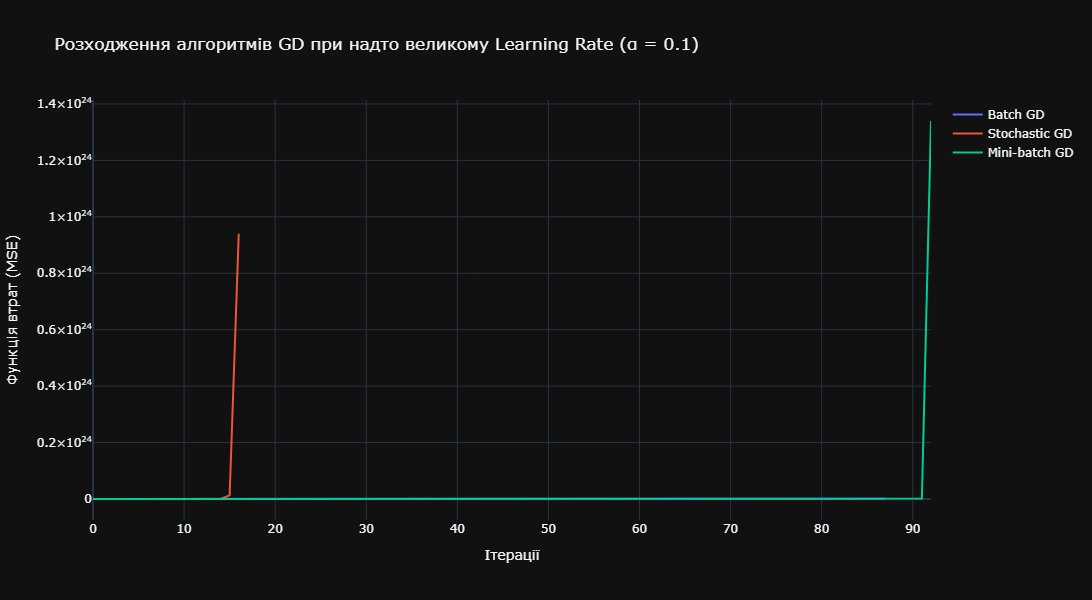

In [40]:
X_train_np = feature_train_ready.to_numpy()
y_train_np = target_train.to_numpy()
learning_rate = 0.1
gradient_type = 'batch'
history_batch_div = []
b = 0
w = numpy.zeros(features)
iterations = 0
train(X_train_np, y_train_np, max_iterations=1000, loss_history=history_batch_div)
gradient_type = 'stochastic'
history_stochastic_div = []
b = 0
w = numpy.zeros(features)
iterations = 0
train(X_train_np, y_train_np, max_iterations=1000, loss_history=history_stochastic_div)
gradient_type = 'mini_batch'
history_mini_batch_div = []
b = 0
w = numpy.zeros(features)
iterations = 0
train(X_train_np, y_train_np, max_iterations=1000, loss_history=history_mini_batch_div)
fig_div = go.Figure()
fig_div.add_trace(go.Scatter(y=history_batch_div, mode='lines', name='Batch GD', line=dict(color='#636EFA')))
fig_div.add_trace(go.Scatter(y=history_stochastic_div, mode='lines', name='Stochastic GD', line=dict(color='#EF553B')))
fig_div.add_trace(go.Scatter(y=history_mini_batch_div, mode='lines', name='Mini-batch GD', line=dict(color='#00CC96')))
fig_div.update_layout(title="Розходження алгоритмів GD при надто великому Learning Rate (α = " + str(learning_rate) + ")", xaxis_title="Ітерації", yaxis_title="Функція втрат (MSE)",template="plotly_dark",height=600)
fig_div.show()

Під час проведення Експерименту Б було встановлено, що підвищення learning_rate до 0.025 ламає стохастичний градієнт, 0.08 ламає mini-batch, 0.1 усі три.

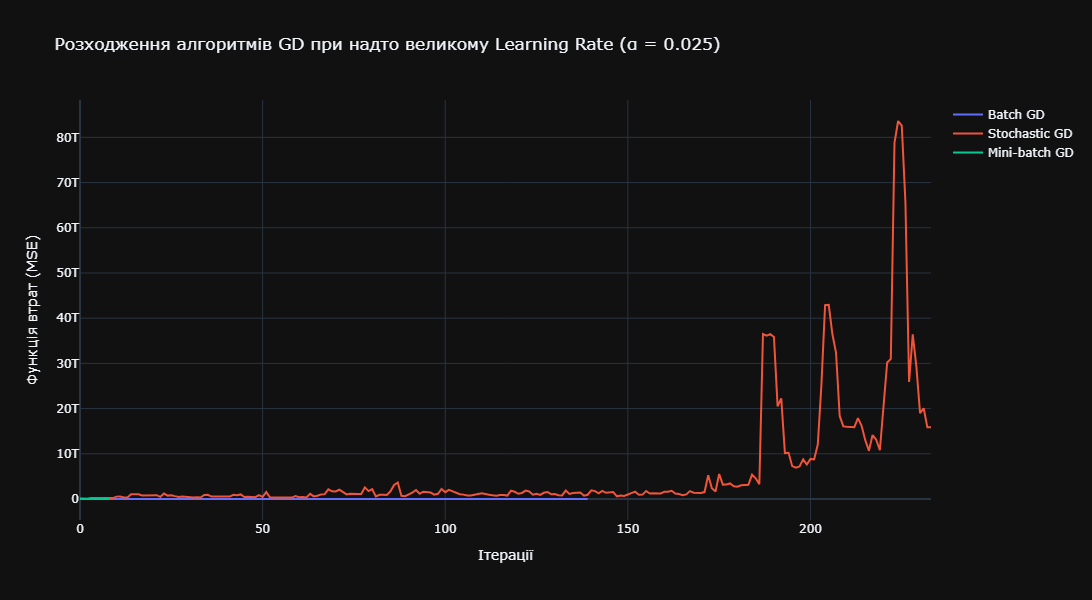
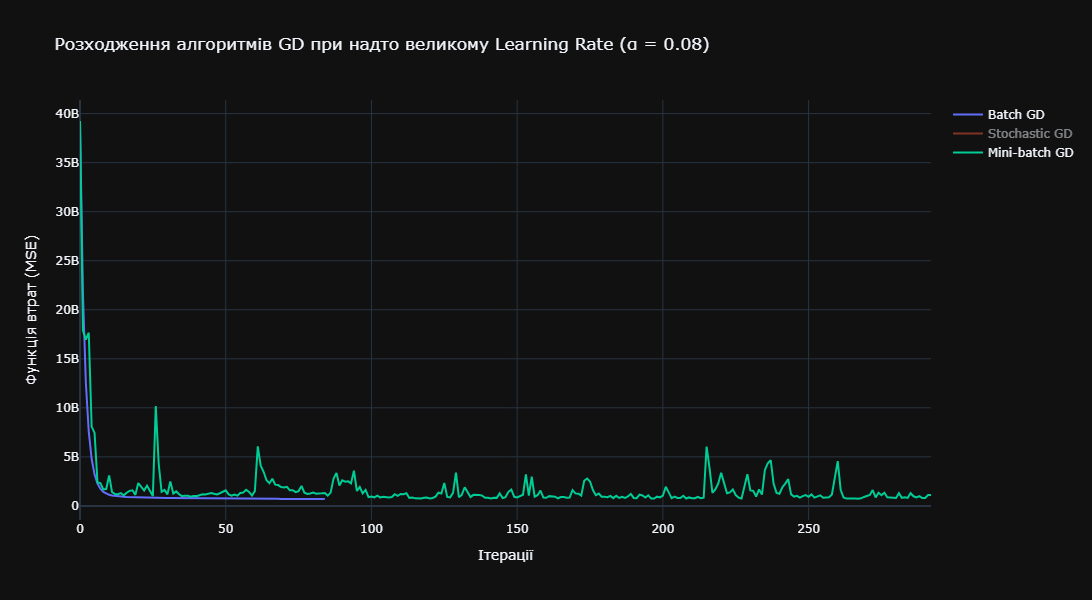
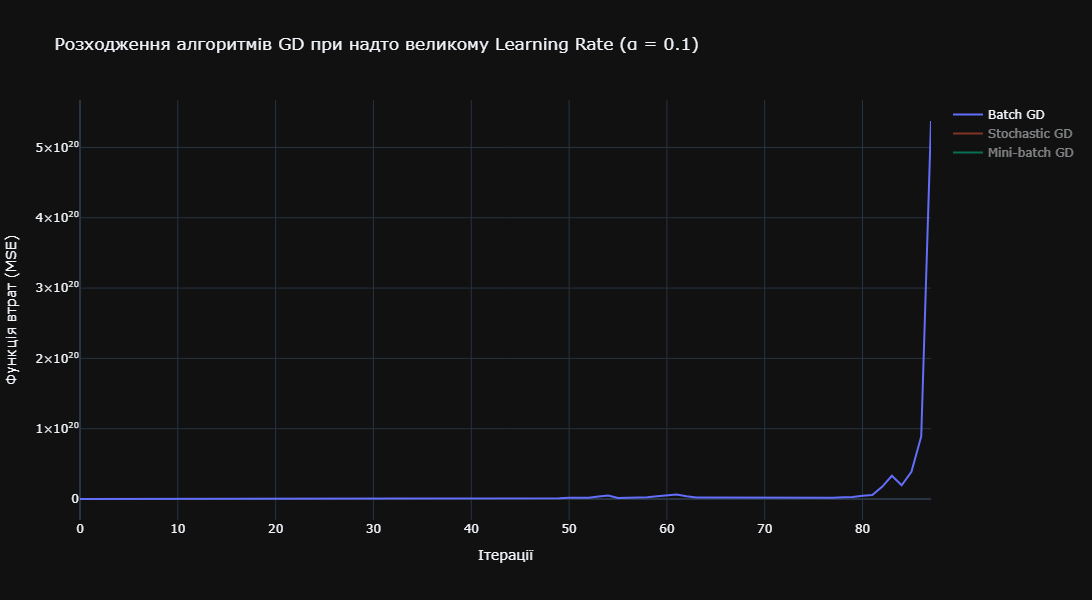